In [16]:
# Step 1: Import libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import precision_score, recall_score, f1_score

print("🎯 Starting Task 3: Handwritten Character Recognition")

🎯 Starting Task 3: Handwritten Character Recognition


In [6]:
# Step 2: Load dataset
print("📥 Loading MNIST Dataset...")
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print("✅ Dataset loaded successfully!")

# Step 3: Data exploration
print(f"📊 Training data shape: {x_train.shape}")
print(f"📊 Test data shape: {x_test.shape}")
print(f"📊 Unique labels: {np.unique(y_train)}")
print(f"🎯 Label distribution in training set:\n{pd.Series(y_train).value_counts().sort_index()}")

# Step 4: Data preprocessing
print("🔄 Preprocessing data...")

# Normalize pixel values
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Reshape data for CNN
x_train = x_train.reshape(x_train.shape[0], 28, 28, 1)
x_test = x_test.reshape(x_test.shape[0], 28, 28, 1)

# Convert labels to categorical
y_train_categorical = to_categorical(y_train, 10)
y_test_categorical = to_categorical(y_test, 10)

print("✅ Data preprocessing completed!")
print(f"📊 Processed training data shape: {x_train.shape}")
print(f"📊 Processed test data shape: {x_test.shape}")

📥 Loading MNIST Dataset...
✅ Dataset loaded successfully!
📊 Training data shape: (60000, 28, 28)
📊 Test data shape: (10000, 28, 28)
📊 Unique labels: [0 1 2 3 4 5 6 7 8 9]
🎯 Label distribution in training set:
0    5923
1    6742
2    5958
3    6131
4    5842
5    5421
6    5918
7    6265
8    5851
9    5949
Name: count, dtype: int64
🔄 Preprocessing data...
✅ Data preprocessing completed!
📊 Processed training data shape: (60000, 28, 28, 1)
📊 Processed test data shape: (10000, 28, 28, 1)


In [7]:
# Step 5: Build CNN model
print("🏗️ Building CNN Model...")

model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

print("✅ Model architecture built successfully!")
model.summary()

🏗️ Building CNN Model...
✅ Model architecture built successfully!


C:\Users\LENOVO\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 3, 3, 64)            │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 576)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 93,322 (364.54 KB)

 Trainable params: 93,322 (364.54 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Step 6: Train the model
print("🔄 Training Model...")
history = model.fit(x_train, y_train_categorical,
                    epochs=10,
                    batch_size=128,
                    validation_split=0.2,
                    verbose=1)

# Step 7: Evaluate the model
print("📊 Evaluating Model...")
test_loss, test_accuracy = model.evaluate(x_test, y_test_categorical, verbose=0)
print(f"✅ Test Accuracy: {test_accuracy:.4f}")
print(f"✅ Test Loss: {test_loss:.4f}")

# Step 8: Make predictions
y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)

🔄 Training Model...
Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.7180 - loss: 0.8559 - val_accuracy: 0.9763 - val_loss: 0.0790
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9547 - loss: 0.1532 - val_accuracy: 0.9839 - val_loss: 0.0550
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9712 - loss: 0.1010 - val_accuracy: 0.9862 - val_loss: 0.0476
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9772 - loss: 0.0810 - val_accuracy: 0.9868 - val_loss: 0.0456
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9809 - loss: 0.0686 - val_accuracy: 0.9877 - val_loss: 0.0416
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9854 - loss: 0.0538 - val_accuracy: 0.9896 - val_loss: 0.0408
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9860 - loss: 0.0492 - val_accuracy: 0.9898 - val_loss: 0.0406
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9877 - los

In [9]:
# Step 9: Detailed evaluation metrics
print("\n📊 Detailed Classification Report:")
print(classification_report(y_test, y_pred_classes))


📊 Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       0.99      1.00      1.00      1135
           2       0.99      1.00      0.99      1032
           3       0.99      1.00      0.99      1010
           4       1.00      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



📈 Creating Visualizations...


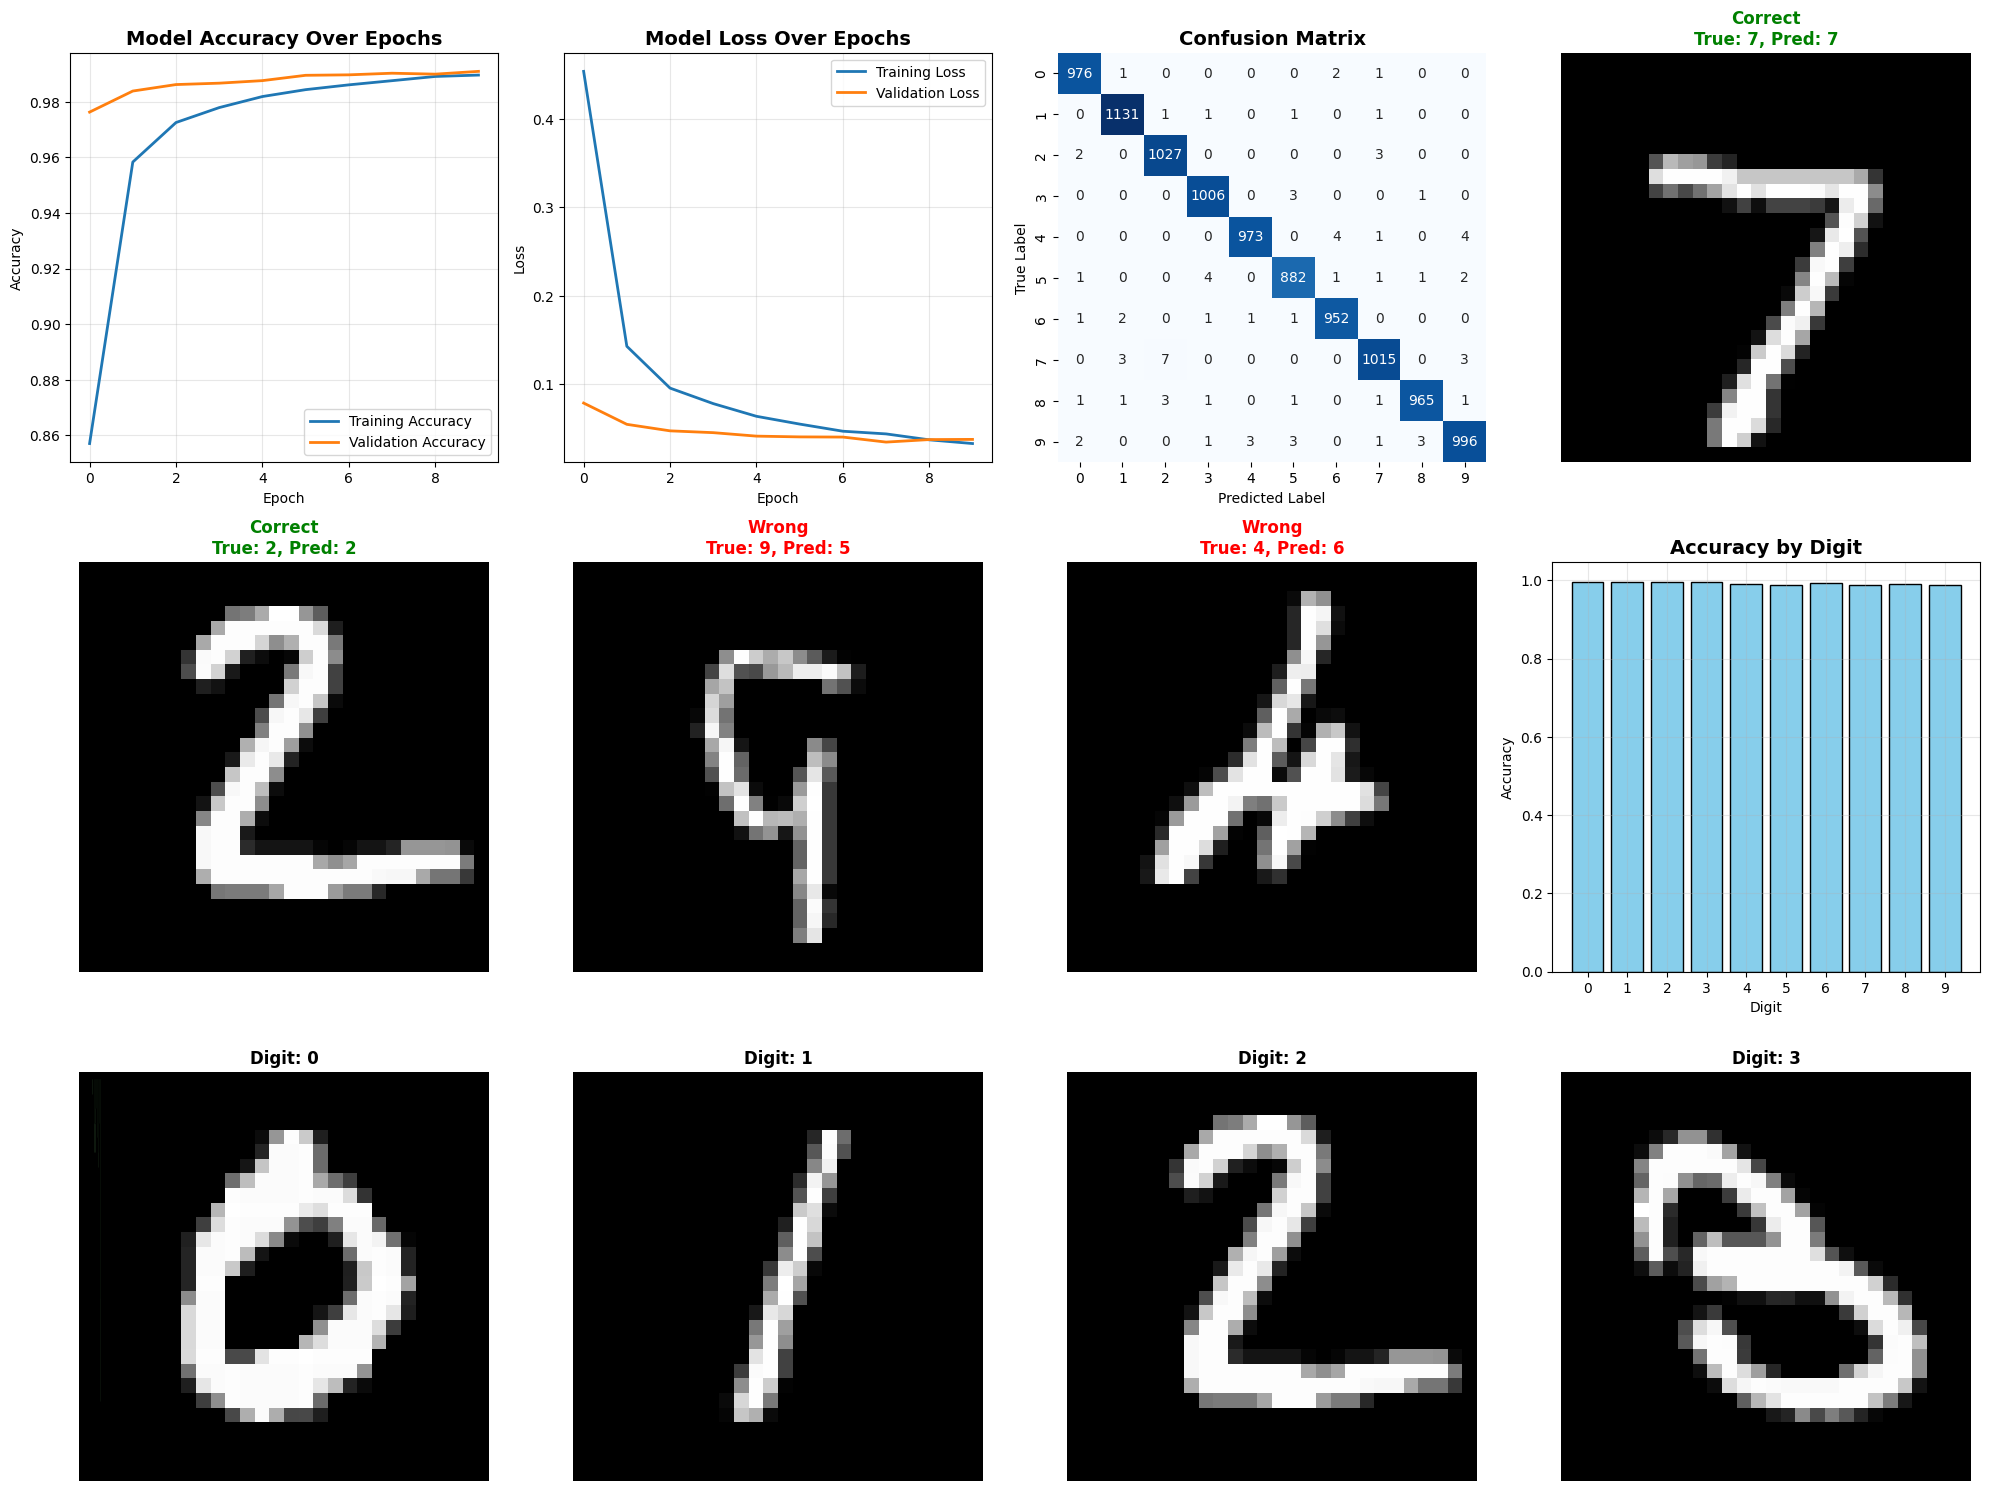


🔍 Detailed Sample Predictions:


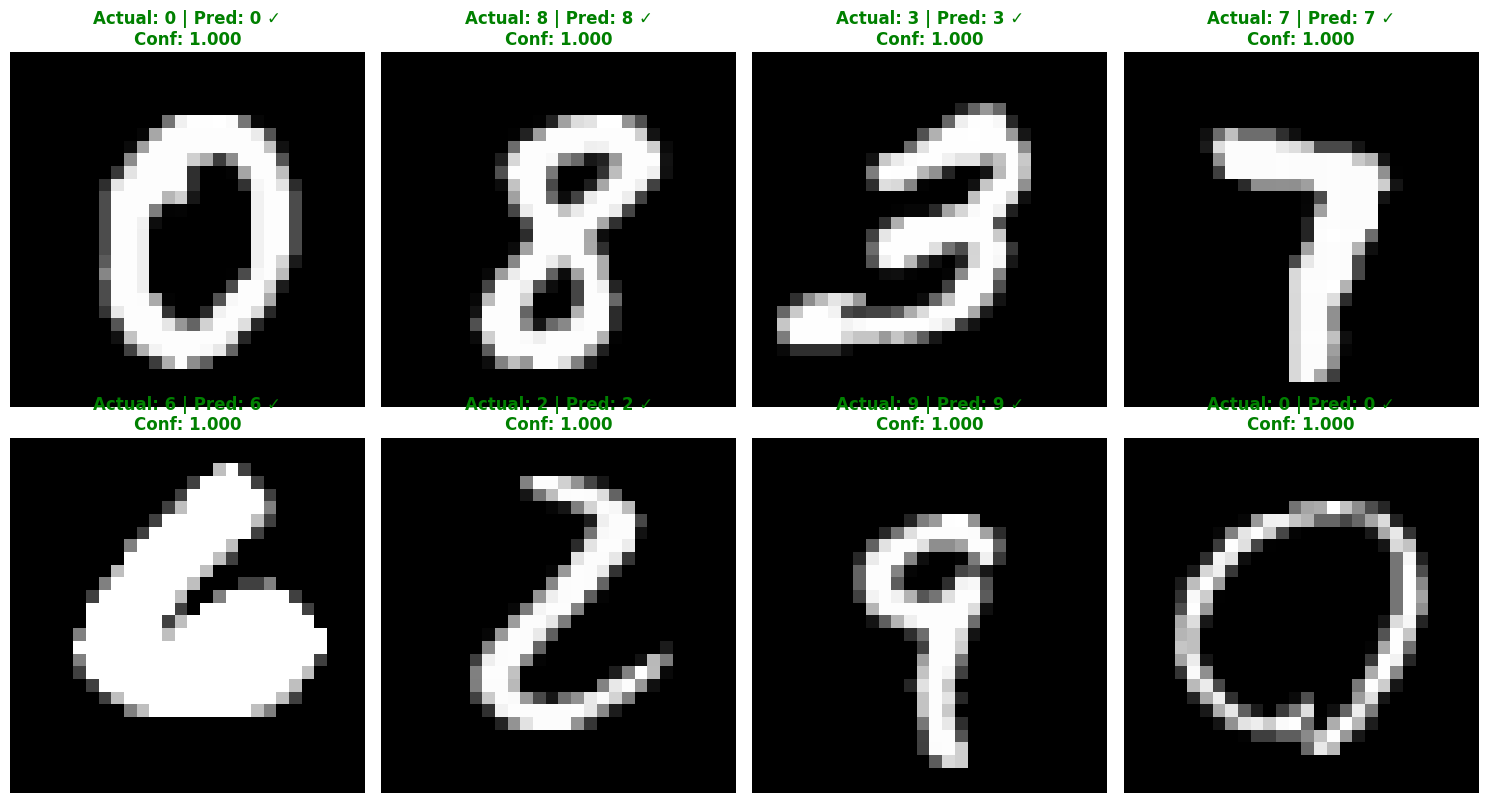

In [12]:
# Step 10: Comprehensive visualizations
print("📈 Creating Visualizations...")
plt.figure(figsize=(20, 15))

# Plot 1: Training history - Accuracy
plt.subplot(3, 4, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
plt.title('Model Accuracy Over Epochs', fontsize=14, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot 2: Training history - Loss
plt.subplot(3, 4, 2)
plt.plot(history.history['loss'], label='Training Loss', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
plt.title('Model Loss Over Epochs', fontsize=14, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot 3: Confusion matrix
plt.subplot(3, 4, 3)
cm = confusion_matrix(y_test, y_pred_classes)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

# Plot 4: Sample predictions grid
plt.subplot(3, 4, 4)
correct_predictions = []
incorrect_predictions = []

for i in range(len(y_test)):
    if y_test[i] == y_pred_classes[i]:
        correct_predictions.append(i)
    else:
        incorrect_predictions.append(i)
    
    if len(correct_predictions) >= 2 and len(incorrect_predictions) >= 2:
        break

# Display correct predictions
for i, idx in enumerate(correct_predictions[:2]):
    plt.subplot(3, 4, 4 + i)
    plt.imshow(x_test[idx].reshape(28, 28), cmap='gray')
    plt.title(f'Correct\nTrue: {y_test[idx]}, Pred: {y_pred_classes[idx]}', 
              color='green', fontweight='bold')
    plt.axis('off')

# Display incorrect predictions
for i, idx in enumerate(incorrect_predictions[:2]):
    plt.subplot(3, 4, 6 + i)
    plt.imshow(x_test[idx].reshape(28, 28), cmap='gray')
    plt.title(f'Wrong\nTrue: {y_test[idx]}, Pred: {y_pred_classes[idx]}', 
              color='red', fontweight='bold')
    plt.axis('off')

# Plot 5: Accuracy by digit
plt.subplot(3, 4, 8)
digit_accuracy = []
for digit in range(10):
    mask = y_test == digit
    if np.sum(mask) > 0:
        accuracy = np.mean(y_pred_classes[mask] == digit)
        digit_accuracy.append(accuracy)

plt.bar(range(10), digit_accuracy, color='skyblue', edgecolor='black')
plt.title('Accuracy by Digit', fontsize=14, fontweight='bold')
plt.xlabel('Digit')
plt.ylabel('Accuracy')
plt.xticks(range(10))
plt.grid(True, alpha=0.3)

# Plot 6: Prediction confidence distribution
plt.subplot(3, 4, 9)
max_probs = np.max(y_pred, axis=1)
plt.hist(max_probs, bins=50, alpha=0.7, color='lightgreen', edgecolor='black')
plt.title('Prediction Confidence Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Maximum Probability')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)

# Plot 7: Sample digit variations
plt.subplot(3, 4, 10)
digit_samples = {}
for digit in range(10):
    indices = np.where(y_test == digit)[0]
    if len(indices) > 0:
        digit_samples[digit] = indices[0]

for i, (digit, idx) in enumerate(list(digit_samples.items())[:4]):
    plt.subplot(3, 4, 9 + i)
    plt.imshow(x_test[idx].reshape(28, 28), cmap='gray')
    plt.title(f'Digit: {digit}', fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

# Step 11: Sample predictions with details
print("\n🔍 Detailed Sample Predictions:")
print("=" * 60)

# Select some random samples
sample_indices = np.random.choice(len(x_test), 8, replace=False)

plt.figure(figsize=(15, 8))
for i, idx in enumerate(sample_indices):
    plt.subplot(2, 4, i + 1)
    plt.imshow(x_test[idx].reshape(28, 28), cmap='gray')
    
    actual = y_test[idx]
    predicted = y_pred_classes[idx]
    confidence = np.max(y_pred[idx])
    
    color = 'green' if actual == predicted else 'red'
    result = '✓' if actual == predicted else '✗'
    
    plt.title(f'Actual: {actual} | Pred: {predicted} {result}\nConf: {confidence:.3f}', 
              color=color, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()


📊 Correct vs Incorrect Examples:


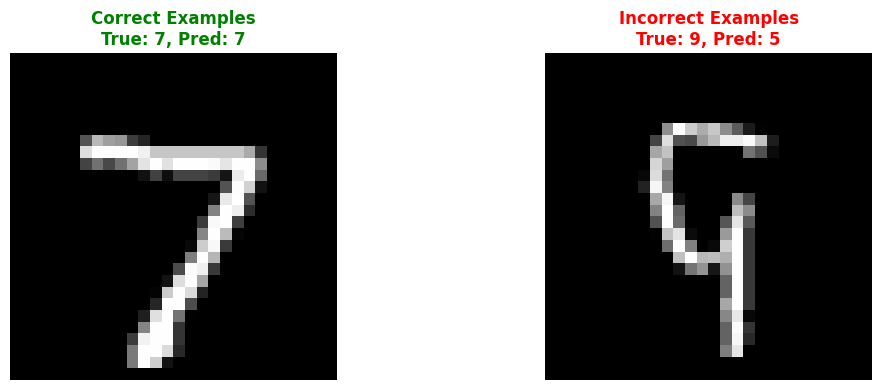

In [13]:
# Step 12: Correct vs incorrect examples
print("\n📊 Correct vs Incorrect Examples:")
plt.figure(figsize=(12, 4))

correct_indices = []
incorrect_indices = []

for i in range(len(y_test)):
    if y_test[i] == y_pred_classes[i]:
        correct_indices.append(i)
    else:
        incorrect_indices.append(i)
    if len(correct_indices) >= 3 and len(incorrect_indices) >= 3:
        break

# Correct predictions
plt.subplot(1, 2, 1)
for i, idx in enumerate(correct_indices[:3]):
    plt.subplot(1, 2, 1)
    if i == 0:
        plt.imshow(x_test[idx].reshape(28, 28), cmap='gray')
        plt.title(f'Correct Examples\nTrue: {y_test[idx]}, Pred: {y_pred_classes[idx]}', 
                  color='green', fontweight='bold')
        plt.axis('off')

# Incorrect predictions  
plt.subplot(1, 2, 2)
for i, idx in enumerate(incorrect_indices[:3]):
    plt.subplot(1, 2, 2)
    if i == 0:
        plt.imshow(x_test[idx].reshape(28, 28), cmap='gray')
        plt.title(f'Incorrect Examples\nTrue: {y_test[idx]}, Pred: {y_pred_classes[idx]}', 
                  color='red', fontweight='bold')
        plt.axis('off')

plt.tight_layout()
plt.show()


In [17]:
# Step 13: Performance summary
print("\n" + "=" * 60)
print("📊 PERFORMANCE SUMMARY")
print("=" * 60)

# Calculate additional metrics
precision = precision_score(y_test, y_pred_classes, average='weighted', zero_division=0)
recall = recall_score(y_test, y_pred_classes, average='weighted')
f1 = f1_score(y_test, y_pred_classes, average='weighted')

print(f"🎯 Test Accuracy: {test_accuracy:.4f}")
print(f"📈 Precision: {precision:.4f}")
print(f"📊 Recall: {recall:.4f}")
print(f"⚡ F1-Score: {f1:.4f}")
print(f"📉 Test Loss: {test_loss:.4f}")

# Correct vs incorrect predictions
correct_count = np.sum(y_test == y_pred_classes)
incorrect_count = len(y_test) - correct_count

print(f"✅ Correct Predictions: {correct_count} ({correct_count/len(y_test)*100:.2f}%)")
print(f"❌ Incorrect Predictions: {incorrect_count} ({incorrect_count/len(y_test)*100:.2f}%)")
print(f"🔢 Total Test Samples: {len(y_test)}")

# Accuracy by digit
print(f"\n📋 Accuracy by Digit:")
for digit in range(10):
    mask = y_test == digit
    if np.sum(mask) > 0:
        digit_acc = np.mean(y_pred_classes[mask] == digit)
        status = "✅" if digit_acc > 0.95 else "⚠️" if digit_acc > 0.90 else "❌"
        print(f"   {status} Digit {digit}: {digit_acc:.4f}")

print("=" * 60)
print("🎉 TASK 3 COMPLETED SUCCESSFULLY!")
print("=" * 60)


📊 PERFORMANCE SUMMARY
🎯 Test Accuracy: 0.9923
📈 Precision: 0.9923
📊 Recall: 0.9923
⚡ F1-Score: 0.9923
📉 Test Loss: 0.0290
✅ Correct Predictions: 9923 (99.23%)
❌ Incorrect Predictions: 77 (0.77%)
🔢 Total Test Samples: 10000

📋 Accuracy by Digit:
   ✅ Digit 0: 0.9959
   ✅ Digit 1: 0.9965
   ✅ Digit 2: 0.9952
   ✅ Digit 3: 0.9960
   ✅ Digit 4: 0.9908
   ✅ Digit 5: 0.9888
   ✅ Digit 6: 0.9937
   ✅ Digit 7: 0.9874
   ✅ Digit 8: 0.9908
   ✅ Digit 9: 0.9871
🎉 TASK 3 COMPLETED SUCCESSFULLY!


# thank you